Machine Learning

In [ ]:
# ===== INICIA SECCIÓN 1: Importación de librerías =====
import kagglehub #descargar el dataset
from torchvision import datasets, transforms #crear y entrenar el modelo cnn
from torch.utils.data import DataLoader, random_split  #crear y entrenar el modelo cnn
from matplotlib import pyplot as plt #visualizar los resultados
from pathlib import Path
import torch.nn as nn #crear y entrenar el modelo cnn
import torch #crear y entrenar el modelo cnn
import torch.nn.functional as F  #crear y entrenar el modelo cnn
from tqdm import tqdm #para mostrar barras de progreso al entrenar
import os
from PIL import Image # para manejar imagenes individuales

In [ ]:
# ===== INICIA SECCIÓN 2: Carga de datos desde KaggleHub =====
path = kagglehub.dataset_download("aryashah2k/indian-medicinal-leaves-dataset")
print("Path to dataset files:", path)
# Apuntar al subdirectorio correcto que contiene las clases
data_root_dir = Path(path) / "Indian Medicinal Leaves Image Datasets" / "Medicinal Leaf dataset"
# ===== FINALIZA SECCIÓN 2 =====

Path to dataset files: /kaggle/input/indian-medicinal-leaves-dataset


In [ ]:
# ===== INICIA SECCIÓN 3: Transformaciones y carga del dataset =====
transform = transforms.Compose([ #agrupa varias transformaciones que se aplicarán en el orden a cada imagen
    transforms.Resize((28, 28)), #redimensiona el tamaño de las imágenes a 28x28 píxeles
    transforms.ToTensor(),#Convierte la imagen en un tensor(formato que entiende pythorch), reescala los valores en un rango de [0,1]
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3) # Normaliza los valores de los pixeles con la finalidad de que el modelo aprenda mejor
])

full_dataset = datasets.ImageFolder(root=data_root_dir, transform=transform)#carga las imagenes organizadas en carpetas, Aplica las transformaciones definidas antes (resize, tensor, normalize) a cada imagen del dataset.


total_size = len(full_dataset) #Calcula cuántas imágenes hay en total
val_size = test_size = int(0.15 * total_size) # reserva 15% del dataset para validación y test
train_size = total_size - val_size - test_size #el resto 70% para el entrenamiento

train_data, validation_data, test_data = random_split(full_dataset, [train_size, val_size, test_size])
train_loader = DataLoader(train_data, batch_size=64, shuffle=True) #batch_size=64 significa que se procesarán 64 imágenes a la vez
validation_loader = DataLoader(validation_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print(f"Clases: {full_dataset.classes}")
print(f"Train: {len(train_loader.dataset)}")
print(f"Val: {len(validation_loader.dataset)}")
print(f"Test: {len(test_loader.dataset)}")
# ===== FINALIZA SECCIÓN 3 =====

Clases: ['Aloevera', 'Amla', 'Amruthaballi', 'Arali', 'Astma_weed', 'Badipala', 'Balloon_Vine', 'Bamboo', 'Beans', 'Betel', 'Bhrami', 'Bringaraja', 'Caricature', 'Castor', 'Catharanthus', 'Chakte', 'Chilly', 'Citron lime (herelikai)', 'Coffee', 'Common rue(naagdalli)', 'Coriender', 'Curry', 'Doddpathre', 'Drumstick', 'Ekka', 'Eucalyptus', 'Ganigale', 'Ganike', 'Gasagase', 'Ginger', 'Globe Amarnath', 'Guava', 'Henna', 'Hibiscus', 'Honge', 'Insulin', 'Jackfruit', 'Jasmine', 'Kambajala', 'Kasambruga', 'Kohlrabi', 'Lantana', 'Lemon', 'Lemongrass', 'Malabar_Nut', 'Malabar_Spinach', 'Mango', 'Marigold', 'Mint', 'Neem', 'Nelavembu', 'Nerale', 'Nooni', 'Onion', 'Padri', 'Palak(Spinach)', 'Papaya', 'Parijatha', 'Pea', 'Pepper', 'Pomoegranate', 'Pumpkin', 'Raddish', 'Rose', 'Sampige', 'Sapota', 'Seethaashoka', 'Seethapala', 'Spinach1', 'Tamarind', 'Taro', 'Tecoma', 'Thumbe', 'Tomato', 'Tulsi', 'Turmeric', 'ashoka', 'camphor', 'kamakasturi', 'kepala']
Train: 4830
Val: 1035
Test: 1035


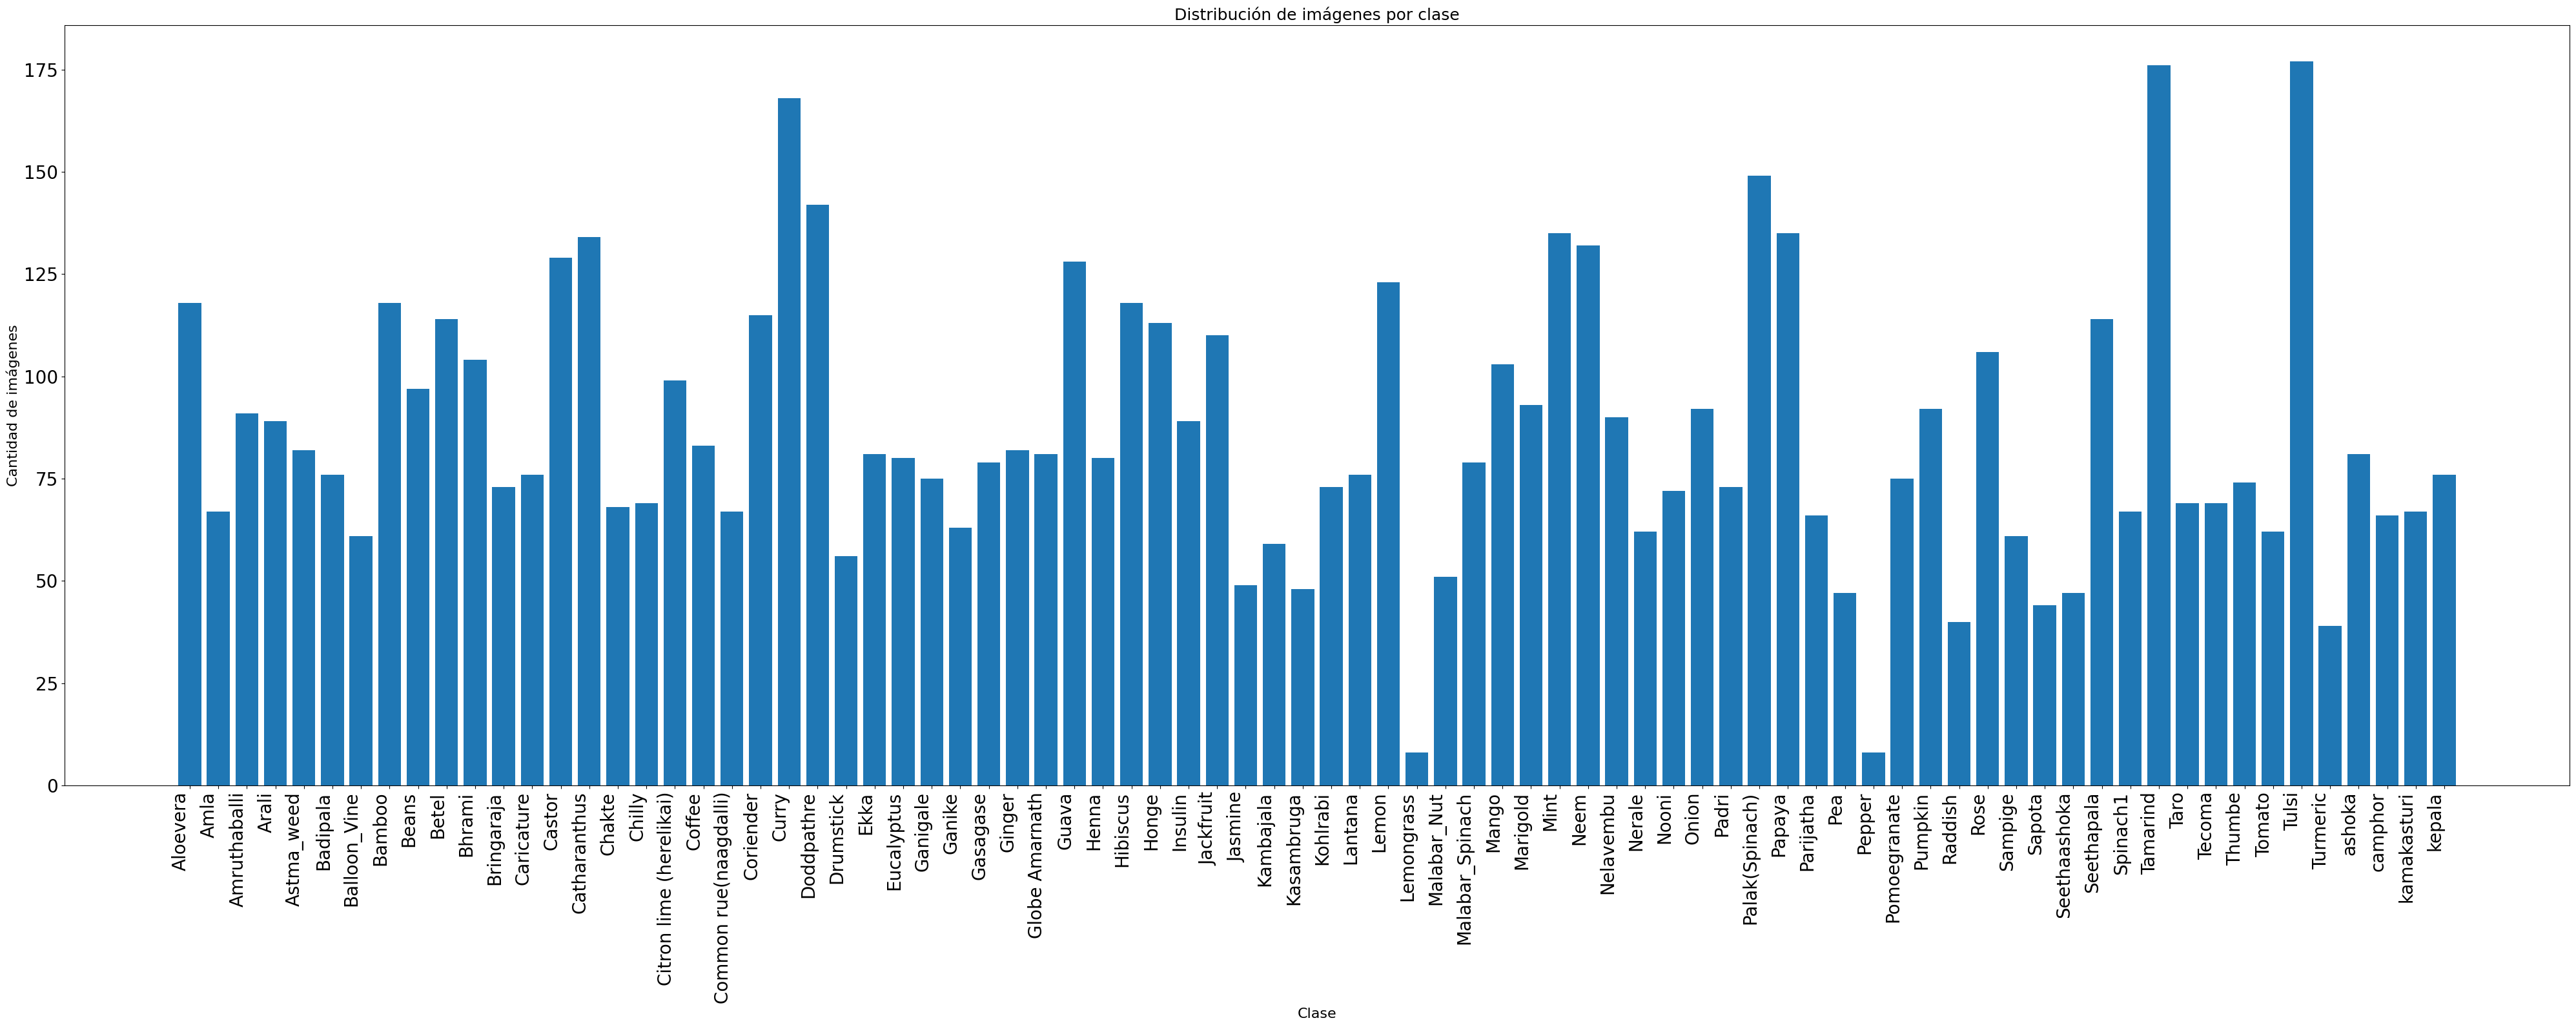

In [ ]:
from collections import Counter
# Conteo de imágenes por clase
counts = Counter(full_dataset.targets)
class_names  = full_dataset.classes
image_counts = [counts[i] for i in range(len(class_names))]

# 🖼️ Figura más grande
plt.figure(figsize=(40, 16))

# 📊 Gráfico
plt.bar(class_names, image_counts)

# 🔤 Etiquetas más grandes y rotadas
plt.xticks(rotation=90, ha='right', fontsize=20)
plt.yticks(fontsize=20)

# 💬 Etiquetas de ejes y título en mayor tamaño
plt.xlabel("Clase", fontsize=16)
plt.ylabel("Cantidad de imágenes", fontsize=16)
plt.title("Distribución de imágenes por clase", fontsize=18)

plt.tight_layout()
plt.show()


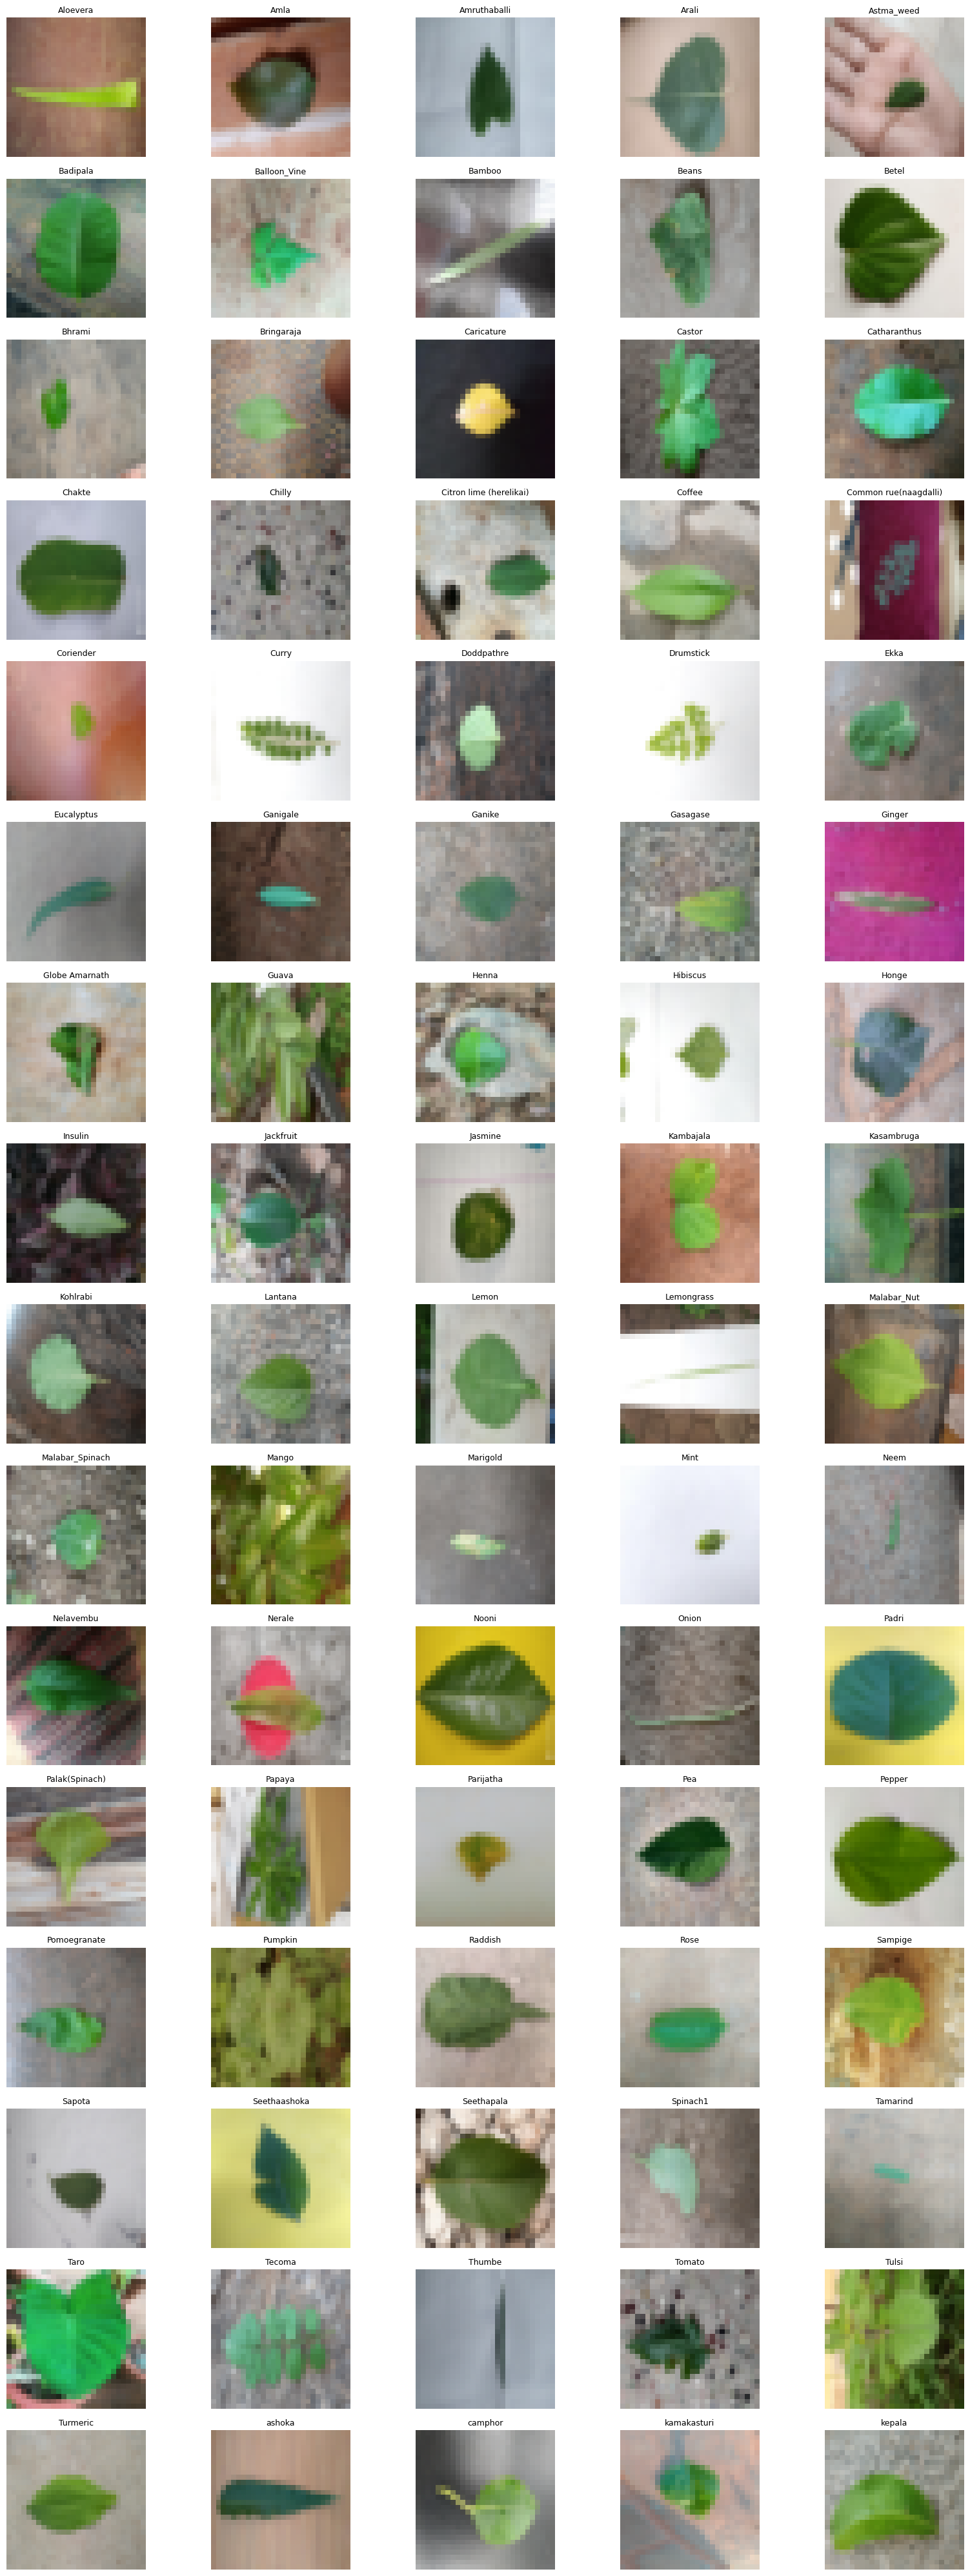

In [ ]:
# ===== INICIA SECCIÓN 4: Visualización del dataset (una imagen por clase) =====
# Seleccionar una imagen por clase
ejemplares_por_clase = {} # Recorre todas las muestras y guarda la primera imagen que encuentra de cada clase en el diccionario.
for ruta_img, etiqueta in full_dataset.samples:
    clase = full_dataset.classes[etiqueta]
    if clase not in ejemplares_por_clase:
        ejemplares_por_clase[clase] = ruta_img
    if len(ejemplares_por_clase) == len(full_dataset.classes):
        break

# Visualización
columnas = 5
filas = (len(ejemplares_por_clase) // columnas) + 1
plt.figure(figsize=(16, filas * 2.5))

for i, (clase, ruta) in enumerate(sorted(ejemplares_por_clase.items())):
    img = Image.open(ruta).convert("RGB") #Abre la imagen desde la ruta especificada y la convierte a formato RGB.
    img = transform(img) * 0.5 + 0.5 #Aplica la tranformación y luego se multiplica para que los valores sean visibles al graficar
    img = img.permute(1, 2, 0)

    plt.subplot(filas, columnas, i + 1)
    plt.imshow(img)
    plt.title(clase, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()
# ===== FINALIZA SECCIÓN 4 =====

In [ ]:
# ===== INICIA SECCIÓN 5: Definición del modelo CNN =====
class PlantCNN(nn.Module):
    def __init__(self, num_classes):
        super(PlantCNN, self).__init__()                        #nn.Conv2d recibe como argumento el número de canales de entrada, el número de canales de salida, el tamaño del kernel y el padding
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1) #kernel_size=3, padding=1 , significa que la salida tendrá el mismo tamaño que la entrada
                                                                # Conv2d recibe 3 canales de entrada (RGB), y produce 32 canales de salida
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = F.relu(self.fc1(x))
        return self.fc2(x)
#IMPORANTE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PlantCNN(num_classes=len(full_dataset.classes)).to(device)

# ===== FINALIZA SECCIÓN 5 =====

In [ ]:
# ===== INICIA SECCIÓN 6: Configuración de entrenamiento =====
criterion = nn.CrossEntropyLoss()      #la función de pérdida CrossEntropyLoss es adecuada para clasificación multiclase
#softmax en este caso es expresado implícitamente en la función de pérdida CrossEntropyLoss
# CrossEntropyLoss combina softmax y la pérdida de entropía cruzada en una sola función
# CrossEntropyLoss calcula la probabilidad de cada clase y luego calcula la pérdida en función de las etiquetas verdaderas
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #Adam es un optimizador que ajusta la tasa de aprendizaje para cada parámetro
# ===== FINALIZA SECCIÓN 6 =====



In [ ]:
# ===== INICIA SECCIÓN 7: Entrenamiento del modelo =====
epochs = 10                        #una época es una pasada completa por todo el dataset
hist_acc_train, hist_acc_val = [], []
hist_loss_train, hist_loss_val = [], []

for epoch in range(epochs):
    print(f"\n🔁 Época {epoch+1}/{epochs}")
    model.train()
    total_loss = total_acc = 0

    for inputs, labels in tqdm(train_loader):  #el batch_size es 64, por lo que cada iteración procesa 64 imágenes
        inputs, labels = inputs.to(device), labels.to(device) #el backward significa que se calcularán los gradientes para cada parámetro del modelo
        optimizer.zero_grad() #mientras que el forward significa que se calculará la salida del modelo para cada imagen del batch
        outputs = model(inputs)
        loss = criterion(outputs, labels) #loos es la función de pérdida que mide qué tan bien el modelo está prediciendo las etiquetas
        loss.backward()                  #loos mientras mas bajo mejor, significa que el modelo está haciendo buenas predicciones
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1) #en este codigo se recorren los pixecs de la imagen y se calcula la salida del modelo para cada imagen del batch
        total_acc += (preds == labels).sum().item() #la cantidad de cuantos pixeles fueron clasificados correctamente se suma a total_acc y el desplazamiento de los pixeles se calcula con el método sum().item()

    epoch_loss = total_loss / len(train_loader)
    epoch_acc = total_acc / len(train_loader.dataset)
    hist_loss_train.append(epoch_loss)
    hist_acc_train.append(epoch_acc)
    print(f"✅ Train - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.4f}")

    # Validación
    model.eval()
    val_loss = val_acc = 0
    with torch.no_grad():
        for inputs, labels in validation_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            val_acc += (preds == labels).sum().item()
#en este codigo se recorren los pixecs de la imagen y se calcula la salida del modelo para cada imagen del batch
#la cantidad de cuantos pixeles fueron clasificados correctamente se suma a total_acc y el desplazamiento de los pixeles se calcula con el método sum().item()


    val_loss /= len(validation_loader)
    val_acc /= len(validation_loader.dataset)
    hist_loss_val.append(val_loss)
    hist_acc_val.append(val_acc)
    print(f"🔎 Val  - Loss: {val_loss:.4f} - Accuracy: {val_acc:.4f}")
# ===== FINALIZA SECCIÓN 7 =====


🔁 Época 1/10


100%|██████████| 76/76 [04:15<00:00,  3.36s/it]


✅ Train - Loss: 4.0460 - Accuracy: 0.0679
🔎 Val  - Loss: 3.6810 - Accuracy: 0.1092

🔁 Época 2/10


100%|██████████| 76/76 [04:14<00:00,  3.35s/it]


✅ Train - Loss: 3.3084 - Accuracy: 0.1776
🔎 Val  - Loss: 3.1176 - Accuracy: 0.2193

🔁 Época 3/10


100%|██████████| 76/76 [04:09<00:00,  3.29s/it]


... (6 outputs left out)

✅ Train - Loss: 1.8965 - Accuracy: 0.4855
🔎 Val  - Loss: 2.3878 - Accuracy: 0.3787

🔁 Época 7/10


100%|██████████| 76/76 [04:06<00:00,  3.25s/it]


✅ Train - Loss: 1.6766 - Accuracy: 0.5418
🔎 Val  - Loss: 2.2165 - Accuracy: 0.4300

🔁 Época 8/10


 67%|██████▋   | 51/76 [02:45<01:14,  2.97s/it]

In [ ]:
# ===== INICIA SECCIÓN 8: Visualización de desempeño =====
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_loss_train, label='Train Loss')
plt.plot(hist_loss_val, label='Val Loss')
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida por época")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(hist_acc_train, label='Train Acc')
plt.plot(hist_acc_val, label='Val Acc')
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.title("Precisión por época")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 🔽 MÉTRICAS ADICIONALES: RECALL, F1-SCORE Y MATRIZ DE CONFUSIÓN 🔽
# ------------------------------------------------------------------
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    f1_score
)

def get_preds_and_labels(model, loader, device):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            preds.append(torch.argmax(logits, dim=1).cpu())
            labels.append(y.cpu())
    return torch.cat(preds), torch.cat(labels)

# ---- Evaluación sobre el conjunto de test ----
test_preds, test_labels = get_preds_and_labels(model, test_loader, device)

all_labels = list(range(len(full_dataset.classes)))  # 0 … 79

print("\n📋  Reporte de clasificación (Test):\n")
print(classification_report(
    test_labels,
    test_preds,
    labels=all_labels,                  # ⬅️ fuerza las 80 clases
    target_names=full_dataset.classes,  # mismas etiquetas en orden
    zero_division=0,                    # evita divisiones por cero
    digits=4
))

# Métricas macro-promediadas
macro_recall = recall_score(test_labels, test_preds,
                            labels=all_labels, average='macro', zero_division=0)
macro_f1     = f1_score(  test_labels, test_preds,
                            labels=all_labels, average='macro', zero_division=0)
print(f"⚙️  Macro Recall: {macro_recall:.4f} | Macro F1-score: {macro_f1:.4f}")

# Matriz de confusión (80×80, clases sin muestras quedan en cero)
cm = confusion_matrix(test_labels, test_preds, labels=all_labels)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=full_dataset.classes).plot(
    ax=ax, xticks_rotation=90, cmap='Blues', colorbar=True
)
plt.title("Matriz de confusión – Test set")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined